In [54]:
# Install the Kaggle package
!pip install kaggle



[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [55]:
import pandas as pd
# Load the dataset
file_path = r"C:\Users\cpall\Desktop\ironhack\amz_uk_price_prediction_dataset.csv"

# Read the CSV file into a DataFrame
df = pd.read_csv(file_path)

# Display basic information about the dataframe
df.info()

KeyboardInterrupt: 

In [ ]:
# Retrieving the number of rows and columns in the dataframe
# (*this command is not useful because  it shows info already given by df.info()*)
df.shape

(2443651, 9)

In [ ]:
# Display the first few rows of the dataframe
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


- The most popular product category is Sports & Outdoors, with a total count of 836,265, representing 34% of the dataset. All other categories are mush smaller, each accounting for less than 1% of observations, with Beauty being the second largest at 0.79% (n = 19,312). This indicates that the marketplace is heavily dominated by Sports & Outdoors, while all other categories have very small representation, indicating a highly skewed distribution.
- The top 5 most listed product categories in the dataset are:
- Sports & Outdoors – 836,265 listings (~34.2%); Beauty – 19,312 listings (~0.79%); Handmade Clothing, Shoes & Accessories – 19,229 listings (~0.79%);
- Bath & Body – 19,092 listings (~0.78%), Birthday Gifts – 18,978 listings (~0.78%).

In [ ]:
# Part 1: Understanding Product Categories
# Business Question: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

# Frequency Tables:
# Generate a frequency table for the product category.
# Counting and sorting the unique values for each object (string) column in descending order
# Which are the top 5 most listed product categories?

# Frequency table for 'category'
frequency_table = df['category'].value_counts().sort_values(ascending=False)  # value_counts() is sorted in descending order by default, but can be sorted explicitly if needed

# Calculating the proportion of each unique value in the 'category'
proportion_table = df['category'].value_counts(normalize=True).sort_values(ascending=False)
# Convert to percentages
proportion_table = (proportion_table * 100).round(2).astype(str) + '%'

# pd.set_option('display.max_rows', None)   # Show ALL rows
frequency_table, proportion_table

(category
 Sports & Outdoors                                   836265
 Beauty                                               19312
 Handmade Clothing, Shoes & Accessories               19229
 Bath & Body                                          19092
 Birthday Gifts                                       18978
 Manicure & Pedicure Products                         18940
 Skin Care                                            18769
 Make-up                                              18756
 Hair Care                                            18735
 Fragrances                                           18564
 Handmade Gifts                                       18295
 Handmade Home Décor                                  18146
 Luggage and travel gear                              18142
 Handmade Jewellery                                   18044
 Handmade Artwork                                     17878
 Women                                                17772
 Handmade Home & Kitchen Produ

C:\Users\cpall\AppData\Local\Temp\ipykernel_6644\3846213883.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_categories.values, y=top_categories.index, palette='viridis')


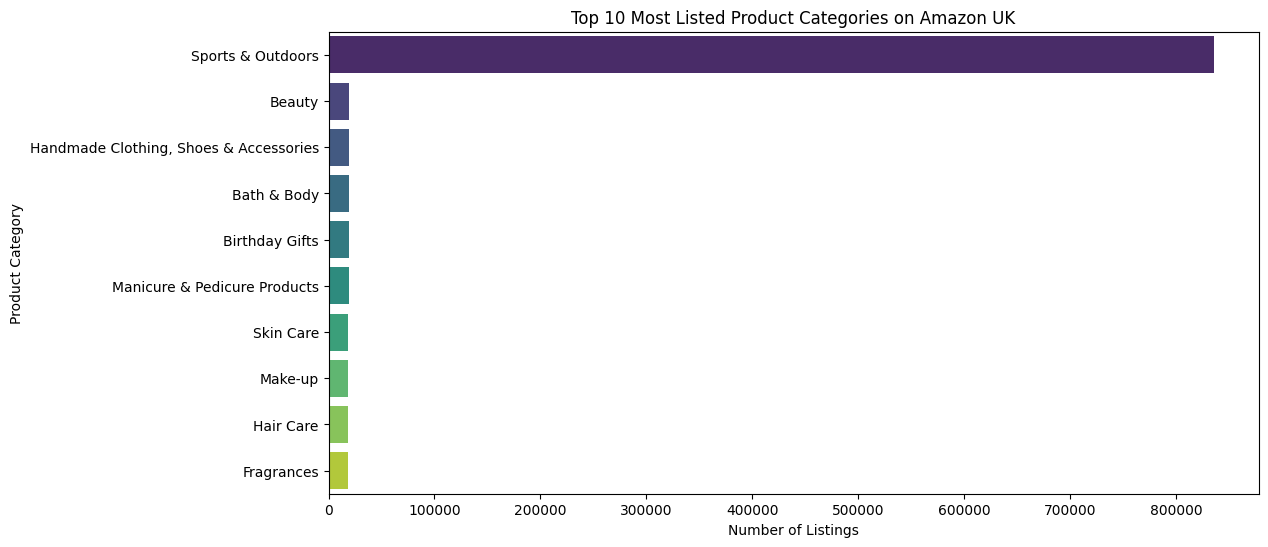

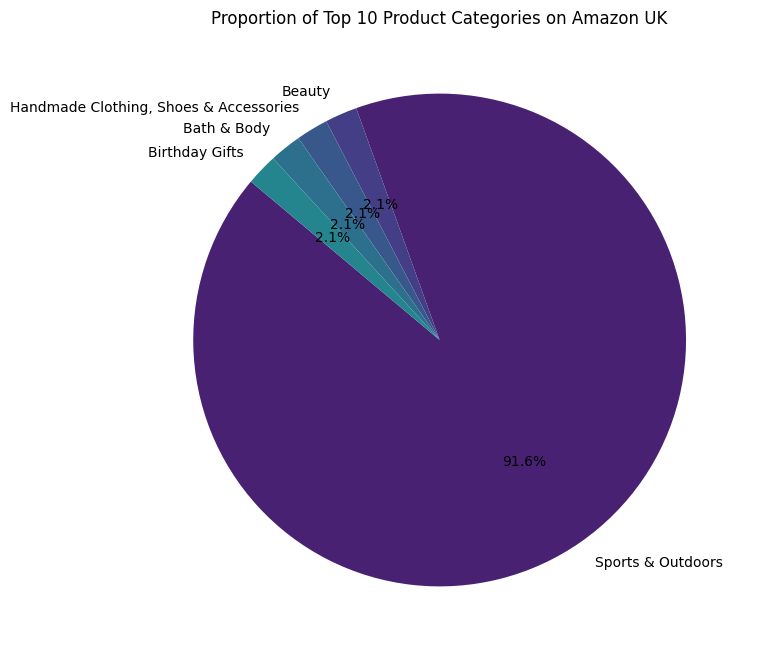

In [ ]:
# Visualizations:
# Display the distribution of products across different categories using a bar chart.
#  If you face problems understanding the chart, do it for a subset of top categories.
# For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Bar chart for top categories

top_categories = frequency_table.head(10)  # Top 10 categories for clarity

plt.figure(figsize=(12,6))
sns.barplot(x=top_categories.values, y=top_categories.index, palette='viridis')
plt.xlabel("Number of Listings")
plt.ylabel("Product Category")
plt.title("Top 10 Most Listed Product Categories on Amazon UK")
plt.show()


# Pie chart for top categories  (autopct='%1.1f%%' automatically displays percentages in the pie chart)
proportion_table = df['category'].value_counts(normalize=True).sort_values(ascending=False)
top_categories_pie = proportion_table.head(5)  # Top 5 categories for pie chart

plt.figure(figsize=(8,8))
plt.pie(top_categories_pie, labels=top_categories_pie.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('viridis', 10))
plt.title("Proportion of Top 10 Product Categories on Amazon UK")
plt.show()



#### Part 2: Delving into Product Pricing
- The average price of products in the dataset is £89.24, but the median price is much lower at £19.09, indicating that the distribution is highly skewed (positive skew or right-skewed distribution) with some very expensive products pulling the mean up.

- The most common price (mode) is £9.99, showing that a large number of products are very cheap compared to the average price.

- While the mean suggests higher prices, most products are actually low-priced, so the mode and median give a better picture of what a typical product costs.

In [ ]:
# Counts the number of non-NaN entries in the selected column.
# There are no missing values in the 'price' column
df["price"].count()

np.int64(2443651)

In [ ]:
# Part 2: Delving into Product Pricing
# Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

# Measures of Centrality:
# Calculate the mean, median, and mode for the price of products.
# What's the average price point of products listed? How does this compare with the most common price point (mode)?

mean_price = df["price"].mean()
median_price = df["price"].median()
mode_price = df["price"].mode()

# Using round()
mean_price = round(df["price"].mean(), 2)

print("Mean price:", mean_price)
print("Median price:", df["price"].median())
print("Mode price:", df["price"].mode()[0])  # mode() returns a Series, so we take the first element

Mean price: 89.24
Median price: 19.09
Mode price: 9.99


- Product Price Variation Analysis

- Variance: 119,445 → indicates a very large spread in prices.
- Standard Deviation: 345.61 → most product prices deviate substantially from the mean.
- Price Range: 0 → 100,000 → extremely wide, showing some very expensive products.
- Interquartile Range (IQR: Q1-Q3): 9.99 – 45.99 → the middle 50% of products are priced much lower than the extreme maximum.
- The very high CV means that the data are highly dispersed relative to the mean.
- The data is highly skewed, with a few very expensive products driving up the variance and standard deviation. Most products are concentrated at lower price points, as reflected in the IQR and median (19.09). This suggests the presence of outliers.

In [ ]:
# Measures of Dispersion:

# Determine the variance, standard deviation, range, and interquartile range for product price.
# How varied are the product prices? Are there any indicators of a significant spread in prices?

variance_price = df['price'].var()
std_dev_price = df['price'].std()
min_price = df['price'].min()
max_price = df['price'].max()
range_price = max_price - min_price
quantiles_price = df['price'].quantile([0.25, 0.5, 0.75])

cv = (std_dev_price / mean_price) # Coefficient of Variation

# print : variance_price, std_dev_price, min_price, max_price, range_price, quantiles_price, cv

print(f"Variance of price: {variance_price:.2f}")
print(f"Standard deviation of price: {std_dev_price:.2f}")
print(f"Minimum price: {min_price:.2f}")
print(f"Maximum price: {max_price:.2f}")
print(f"Range of price: {range_price:.2f}")
print("Price quantiles:")
print(quantiles_price.round(2))
print(f"Coefficient of variation (CV): {cv:.2f}")

# variance_price, std_dev_price, min_price, max_price, range_price, quantiles_price, cv


Variance of price: 119445.49
Standard deviation of price: 345.61
Minimum price: 0.00
Maximum price: 100000.00
Range of price: 100000.00
Price quantiles:
0.25     9.99
0.50    19.09
0.75    45.99
Name: price, dtype: float64
Coefficient of variation (CV): 3.87


- Visualizing the data in the histogram is difficult because a few extremely expensive products stretch the x-axis. This compresses the low-price bins, making the histogram hard to interpret. To address this, the variable is transformed using a logarithmic scale.

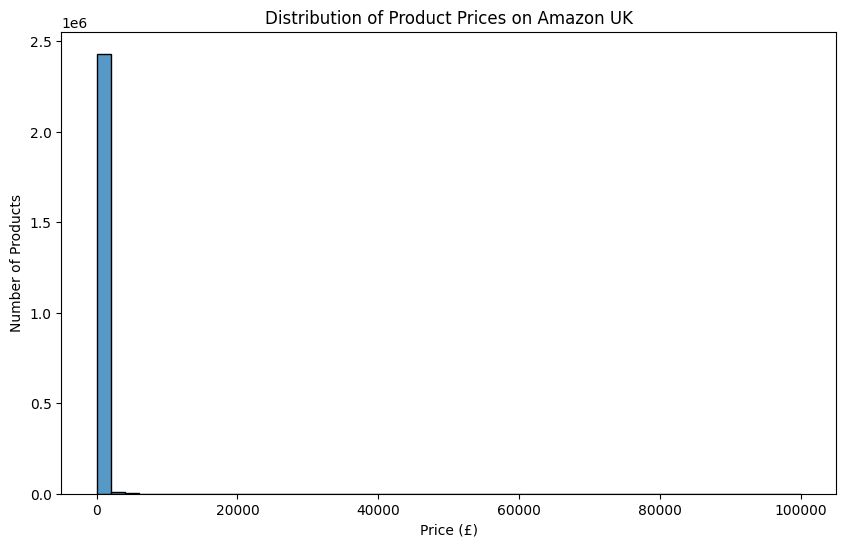

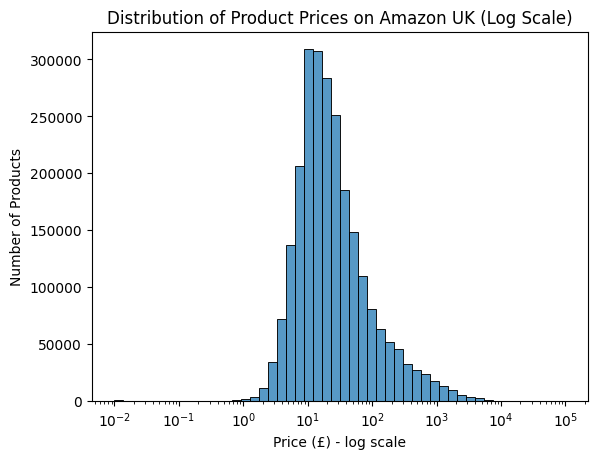

In [ ]:
# Visualizations:

# Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices.
# If its hard to read these diagrams, think why this is, and explain how it could be solved..

import matplotlib.pyplot as plt
import seaborn as sns

# Basic histogram of product prices
plt.figure(figsize=(10,6))
sns.histplot(df['price'], bins=50, kde=False)
plt.title("Distribution of Product Prices on Amazon UK")
plt.xlabel("Price (£)")
plt.ylabel("Number of Products")
plt.show()

# Histogram with log scale on x-axis to better visualize the distribution reducing the effect of extreme values
sns.histplot(df['price'], bins=50, log_scale=(True, False))   # log_scale=(True, False) applies a log scale only to the x-axis
plt.xlabel("Price (£) - log scale")
plt.ylabel("Number of Products")
plt.title("Distribution of Product Prices on Amazon UK (Log Scale)")
plt.show()


- In the dataset, outliers are identified using the lower and upper whiskers. Specifically, some products have prices exceeding the upper whisker, classifying them as upper outliers. A box plot is then produced to show the distribution of the price variable, excluding these outliers.
- The box plot shows the median, first quartile (Q1), third quartile (Q3), and the whiskers. The percentiles used in the plot correspond to those calculated previously in the code.

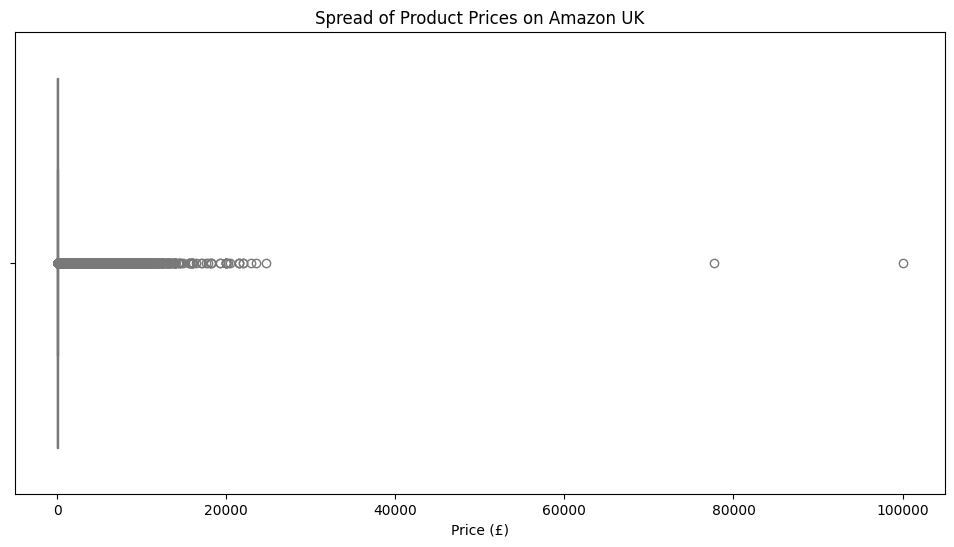

Lower whisker: -44.01
Upper whisker: 99.99000000000001


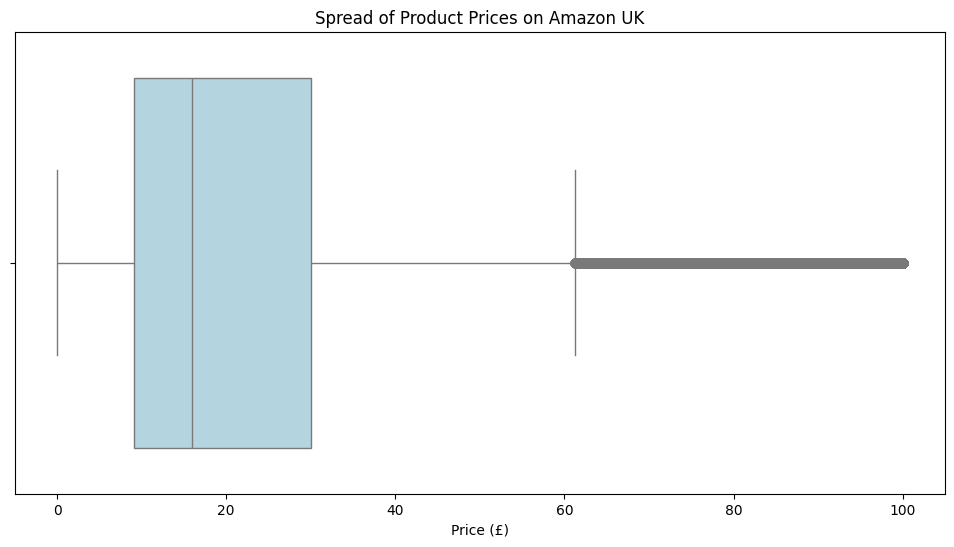

In [ ]:
# Are there products that are priced significantly higher than the rest?
# Use a box plot to showcase the spread and potential outliers in product pricing.
import matplotlib.pyplot as plt
import seaborn as sns

# Plotting a boxplot for the 'SalePrice' column with a light blue color

plt.figure(figsize=(12,6))
sns.boxplot(x=df['price'], color="lightblue")
plt.title("Spread of Product Prices on Amazon UK")
plt.xlabel("Price (£)")
plt.show()


# Calculate quartiles
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

# Calculate whiskers
lower_whisker = Q1 - 1.5 * IQR
upper_whisker = Q3 + 1.5 * IQR

print("Lower whisker:", lower_whisker)
print("Upper whisker:", upper_whisker)

# Optional: filter out extreme outliers
df_no_outliers = df[df['price'] <= upper_whisker]

plt.figure(figsize=(12,6))
sns.boxplot(x=df_no_outliers['price'], color="lightblue")
plt.title("Spread of Product Prices on Amazon UK")
plt.xlabel("Price (£)")
plt.show()


- 

In [ ]:
# Part 3: Unpacking Product Ratings
# Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

# Measures of Centrality:
# Calculate the mean, median, and mode for the rating of products.
# How do customers generally rate products? Is there a common trend?

import pandas as pd

# Assuming df is your DataFrame
mean_rating = df['stars'].mean()
median_rating = df['stars'].median()
mode_rating = df['stars'].mode() # mode() returns a pandas Series; can return multiple values, take the first if needed using [0]

print(f"Mean rating: {mean_rating:.2f}")
print(f"Median rating: {median_rating:.2f}")
print(f"Mode rating: {mode_rating}")

Mean rating: 2.15
Median rating: 0.00
Mode rating: 0    0.0
Name: stars, dtype: float64


- The distribution of product ratings is highly variable, with a variance of 4.82 and a standard deviation of 2.19. Ratings range from 0 to 5, but the median and lower quartile are both 0, indicating that many products have no ratings. These 0 values skew the distribution and can be considered outliers. The coefficient of variation (CV = 1.02) further highlights the high relative variability in ratings.

In [ ]:
# Measures of Dispersion:
# Determine the variance, standard deviation, and interquartile range for product rating.
# Are the ratings consistent, or is there a wide variation in customer feedback?

# Calculate variance, standard deviation, min, max, range, and quantiles for 'stars'
variance_rating = df['stars'].var()
std_dev_rating = df['stars'].std()
min_rating = df['stars'].min()
max_rating = df['stars'].max()
range_rating = max_rating - min_rating
quantiles_rating = df['stars'].quantile([0.25, 0.5, 0.75])

mean_rating = df['stars'].mean()
cv_rating = std_dev_rating / mean_rating  # Coefficient of Variation

# Print results
print(f"Variance of rating: {variance_rating:.2f}")
print(f"Standard deviation of rating: {std_dev_rating:.2f}")
print(f"Minimum rating: {min_rating:.2f}")
print(f"Maximum rating: {max_rating:.2f}")
print(f"Range of rating: {range_rating:.2f}")
print("Rating quantiles:")
print(quantiles_rating.round(2))
print(f"Coefficient of variation (CV): {cv_rating:.2f}")

Variance of rating: 4.82
Standard deviation of rating: 2.19
Minimum rating: 0.00
Maximum rating: 5.00
Range of rating: 5.00
Rating quantiles:
0.25    0.0
0.50    0.0
0.75    4.4
Name: stars, dtype: float64
Coefficient of variation (CV): 1.02


In [ ]:
df['stars'].unique()


array([4.7, 4.6, 4.5, 4.8, 0. , 4.4, 4.3, 4.1, 4.9, 5. , 3.8, 3.6, 4. ,
       4.2, 3. , 3.9, 2.5, 3.4, 3.7, 3.2, 3.3, 3.5, 2.7, 2.1, 1. , 3.1,
       2. , 2.9, 2.8, 1.5, 2.2, 2.3, 2.6, 2.4, 1.4, 1.9, 1.8, 1.7, 1.6,
       1.2, 1.3, 1.1])

- The histogram shows that many products have no ratings. These 0 values skew the distribution and can be considered outliers.
- The skewness coefficient of 0.08 indicates very slight positive skewness and the negative kurtosis coefficient indicates a platykurtic distribution.

In [60]:
# Shape of the Distribution:

# Calculate the skewness and kurtosis for the rating column.
# Are the ratings normally distributed, or do they lean towards higher or lower values?
skewness_rating = df['stars'].skew()
kurtosis_rating = df['stars'].kurtosis()
print(f"Skewness of rating: {skewness_rating:.2f}")
print(f"Kurtosis of rating: {kurtosis_rating:.2f}")

Skewness of rating: 0.08
Kurtosis of rating: -1.93


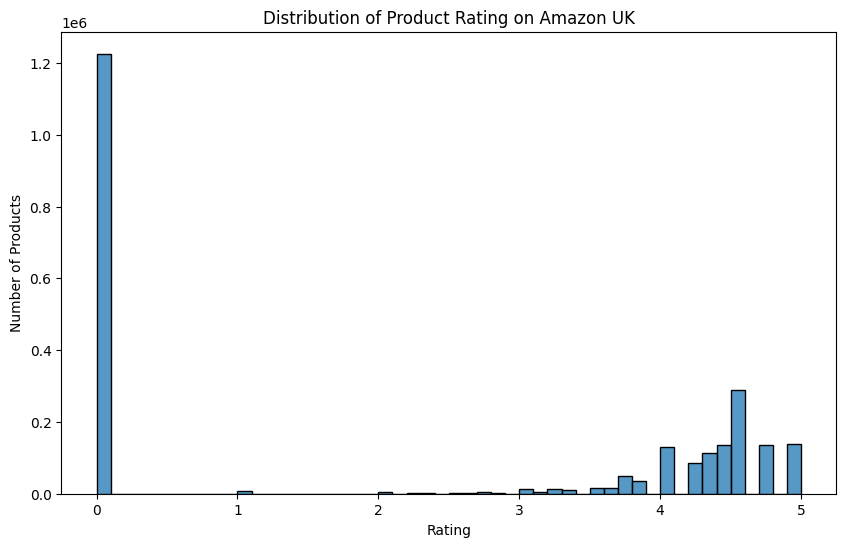

In [62]:
# Visualizations:
# Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?
import matplotlib.pyplot as plt
import seaborn as sns

# Basic histogram of product rating
plt.figure(figsize=(10,6))
sns.histplot(df['stars'], bins=50, kde=False)
plt.title("Distribution of Product Rating on Amazon UK")
plt.xlabel("Rating")
plt.ylabel("Number of Products")
plt.show()

- After removing 0 ratings, the distribution of product ratings is heavily concentrated at the high end (left-skewed) 
- and has a sharp peak with some extreme low ratings (leptokurtic).
- Most products are rated highly, but a few still have low ratings.

Skewness of rating: -2.38
Kurtosis of rating: 9.78


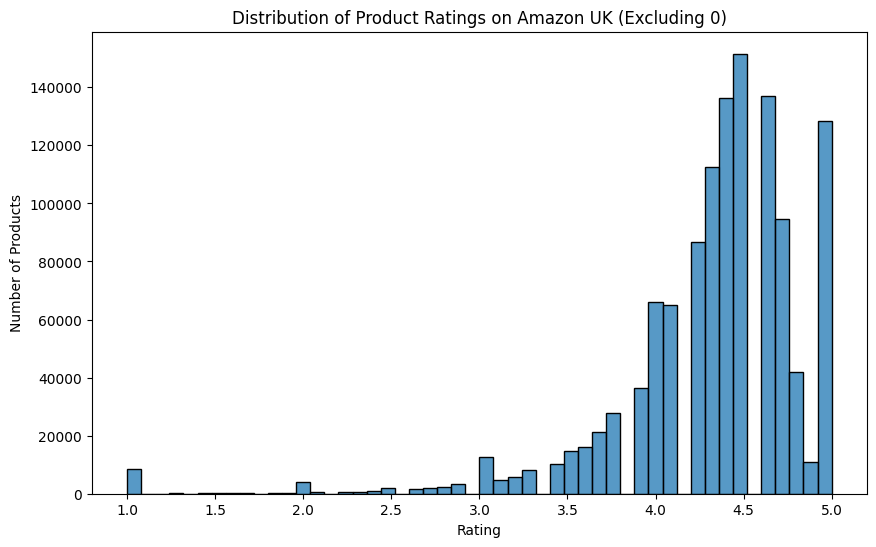

In [64]:
# Filter out zero ratings
df_nonzero = df[df['stars'] > 0]
skewness_rating = df_nonzero['stars'].skew()
kurtosis_rating = df_nonzero['stars'].kurtosis()
print(f"Skewness of rating: {skewness_rating:.2f}")
print(f"Kurtosis of rating: {kurtosis_rating:.2f}")

# Plot histogram
plt.figure(figsize=(10,6))
sns.histplot(df_nonzero['stars'], bins=50, kde=False)
plt.title("Distribution of Product Ratings on Amazon UK (Excluding 0)")
plt.xlabel("Rating")
plt.ylabel("Number of Products")
plt.show()


- The test of normality shows that the data do not follow a normal distribution.

In [65]:
import numpy as np
from scipy.stats import kstest, norm

# Exclude zeros
ratings = df['stars'][df['stars'] != 0]

# Standardize the data (mean=0, std=1) for K-S test against normal distribution
ratings_std = (ratings - ratings.mean()) / ratings.std()

# Kolmogorov-Smirnov test
ks_stat, ks_pvalue = kstest(ratings_std, 'norm')

print(f"KS statistic: {ks_stat:.4f}")
print(f"P-value: {ks_pvalue:.4f}")

if ks_pvalue < 0.05:
    print("The distribution is significantly different from normal (reject H0).")
else:
    print("The distribution does not significantly differ from normal (fail to reject H0).")


KS statistic: 0.1541
P-value: 0.0000
The distribution is significantly different from normal (reject H0).
